In [35]:
import pandas as pd
import matplotlib.pyplot as plt

# load dataset with only neighborhood, dates, and status code columns 
df = pd.read_csv("311-data.csv", usecols = ["neighborhood", "create_date_et", "closed_date_et", "status_code"])

# convert to datatime objects
df["create_date_et"] = pd.to_datetime(df["create_date_et"])
df["closed_date_et"] = pd.to_datetime(df["closed_date_et"])

# ensure numeric status codes
df["status_code"] = pd.to_numeric(df["status_code"], errors="coerce")

# clean data and copy into new independent dataframe
df["neighborhood"] = df["neighborhood"].replace(r"^\s*$", pd.NA, regex=True)
completed = df[(df["status_code"] == 1) & (df["neighborhood"].notna()) & (df["create_date_et"].notna()) & (df["closed_date_et"].notna())].copy()

# remaining rows after cleaning for reference
print("Original records:", len(df))
print("Remaining records:", len(completed))
print("Removed records:", len(df) - len(completed))

Original records: 815417
Remaining records: 689498
Removed records: 125919


In [36]:
# create new column, calculate completion times for requests, store in column
completed["completion_time"] = (completed["closed_date_et"] - completed["create_date_et"]).dt.total_seconds() / 86400

# group requests by neighborhood and calculate median completion time for each neighborhood
neighborhood_stats = completed.groupby("neighborhood")["completion_time"].agg(["median"])

# sort neighborhoods by median in ascending order
neighborhood_stats = neighborhood_stats.sort_values(by="median")

# display neighborhoods with top 20 fastest completion times
neighborhood_stats.head(20)

,median
neighborhood,
Crafton Heights,2.055556
East Carnegie,4.882986
Ridgemont,4.943056
Stanton Heights,5.673611
Summer Hill,5.795833
Glen Hazel,5.935417
Westwood,6.150347
Chartiers City,6.486111
Bedford Dwellings,6.488194


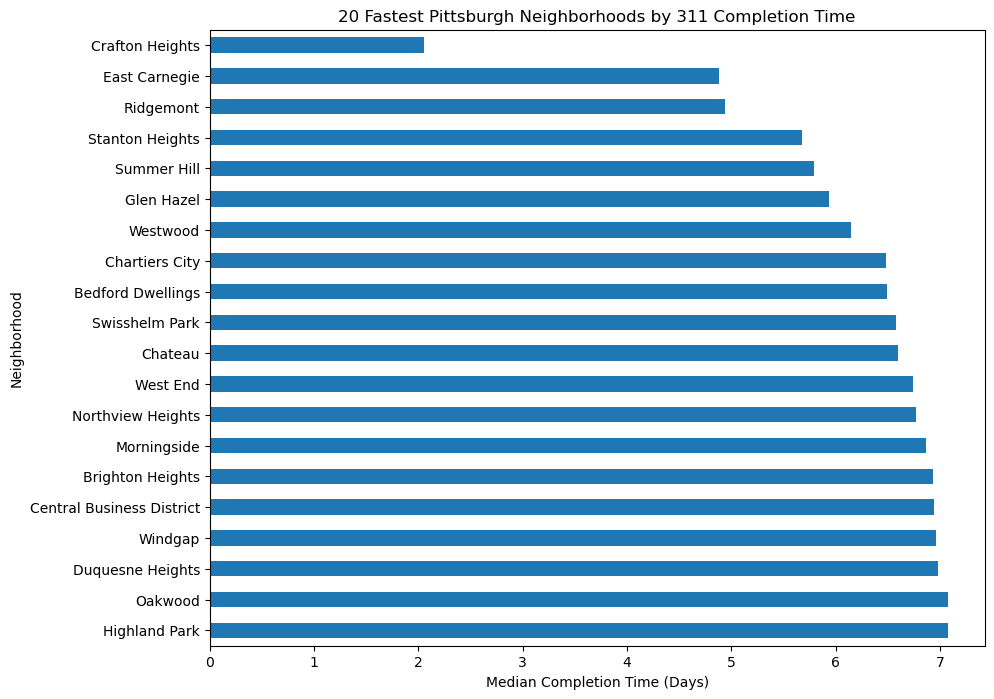

In [37]:
# data visualization

# create series for top 20 fastest request completion neighborhoods
top_20 = neighborhood_stats.head(20)

# create horizontal bar chart for top 20 neighborhoods, sort in ascending order
top_20["median"].sort_values().plot(kind="barh", figsize=(10, 8))
plt.gca().invert_yaxis()

# chart labels
plt.xlabel("Median Completion Time (Days)")
plt.ylabel("Neighborhood")
plt.title("20 Fastest Pittsburgh Neighborhoods by 311 Completion Time")

# display chart
plt.show()